In [1]:
%pip install scikit-learn scipy seaborn pandas numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\USUARIO\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

os.makedirs("outputs", exist_ok=True)

# Moda de una serie ignorando nulos (se usa en los perfiles)
def moda(s):
    s = s.dropna()
    return s.value_counts().index[0] if len(s) else "NA"

# Parte A: aprendizaje no supervisado
Accidentalidad vial de Medellín (2008-2025). Regla: la variable objetivo (víctimas) **no se usa para agrupar**; se usa al final para validar.

# 1. Calidad de datos

In [2]:
df = pd.read_csv("Fatal_Road_Traffic.csv", sep=";", decimal=",",
                 na_values=["N/D", "Sin inf"], low_memory=False)
print(df.shape)
df.head(3)

(702540, 13)


,LLAVE,AÑO,FECHA_INCIDENTE,HORA_INCIDENTE,CLASE_INCIDENTE,GRAVEDAD_INCIDENTE,DIRECCION_INTERPOLADA,Latitud,Longitud,Codigo Comuna Planeacion,Comuna Planeacion,Codigo Barrio Planeacion,Barrio Planeacion
0,1,2008,01/ene/2008,00:10:00,Choque,SOLO DAÑOS,Carrera 40 Con Calle 64,"6,25614811","-75,55431318",8.0,Villa Hermosa,0803,San Miguel
1,2,2008,01/ene/2008,00:30:00,Otro,HERIDO,Calle 13 A Con Carrera 5,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2008,01/ene/2008,00:35:00,Choque,HERIDO,Calle 104 Con Carrera 65,"6,30150066","-75,56622664",5.0,Castilla,0509,Boyacá


In [3]:
df.info()
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 702540 entries, 0 to 702539
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   LLAVE                     702540 non-null  int64  
 1   AÑO                       702540 non-null  int64  
 2   FECHA_INCIDENTE           702540 non-null  str    
 3   HORA_INCIDENTE            702540 non-null  str    
 4   CLASE_INCIDENTE           702540 non-null  str    
 5   GRAVEDAD_INCIDENTE        702540 non-null  str    
 6   DIRECCION_INTERPOLADA     691440 non-null  str    
 7   Latitud                   657755 non-null  str    
 8   Longitud                  657755 non-null  str    
 9   Codigo Comuna Planeacion  674386 non-null  float64
 10  Comuna Planeacion         674386 non-null  str    
 11  Codigo Barrio Planeacion  655808 non-null  str    
 12  Barrio Planeacion         655808 non-null  str    
dtypes: float64(1), int64(2), str(10)
memory usage: 140.0 MB

,LLAVE,AÑO,Codigo Comuna Planeacion
count,702540.00,702540.00,674386.00
mean,351270.50,2015.82,11.65
std,202805.97,4.75,11.70
min,1.00,2008.00,1.00
25%,175635.75,2012.00,7.00
50%,351270.50,2016.00,10.00
75%,526905.25,2020.00,14.00
max,702540.00,2025.00,90.00


In [4]:
meses = {"ene": "01", "feb": "02", "mar": "03", "abr": "04", "may": "05", "jun": "06",
         "jul": "07", "ago": "08", "sep": "09", "oct": "10", "nov": "11", "dic": "12"}
fecha_txt = df["FECHA_INCIDENTE"].astype(str).str.strip().str.lower()
for es, num in meses.items():
    fecha_txt = fecha_txt.str.replace("/" + es + "/", "/" + num + "/", regex=False)
df["fecha"] = pd.to_datetime(fecha_txt, format="%d/%m/%Y", errors="coerce")
print("Fechas que no se pudieron leer:", df["fecha"].isna().sum())   # debe ser 0

df["hora"] = pd.to_numeric(df["HORA_INCIDENTE"].astype(str).str.split(":").str[0], errors="coerce")   # "00:10:00" -> 0
df["dia_semana"] = df["fecha"].dt.dayofweek            # 0 = lunes ... 6 = domingo
df["fin_de_semana"] = (df["dia_semana"] >= 5).astype(int)
df["anio"] = df["fecha"].dt.year

Fechas que no se pudieron leer: 0


In [5]:
print(df["GRAVEDAD_INCIDENTE"].value_counts())
g = df["GRAVEDAD_INCIDENTE"].astype(str).str.lower()
df["con_victimas"] = np.where(g.str.contains("herid|muert"), 1,
                              np.where(g.str.contains("daño|dano"), 0, np.nan))

df = df.rename(columns={"Latitud": "lat", "Longitud": "lon", "CLASE_INCIDENTE": "clase",
                        "Comuna Planeacion": "comuna"})

# Coordenadas a número (si alguna celda tiene texto, queda como NaN)
for c in ["lat", "lon"]:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", "."), errors="coerce")
print(df[["lat", "lon"]].dtypes)

GRAVEDAD_INCIDENTE
HERIDO        400373
SOLO DAÑOS    299405
MUERTO          2762
Name: count, dtype: int64
lat    float64
lon    float64
dtype: object


In [6]:
print(df[["lat", "lon", "hora", "con_victimas"]].isna().mean().round(3))   # ~6% sin coordenadas
n0 = len(df)
df = df.dropna(subset=["lat", "lon", "hora", "con_victimas"])

df = df[df["lat"].between(6.08, 6.42) & df["lon"].between(-75.72, -75.45)].reset_index(drop=True)
print(f"Filas: {n0:,} -> {len(df):,}")


cols = [c for c in df.columns if c != "LLAVE"]
print("Filas repetidas (sin contar LLAVE):", df.duplicated(subset=cols).sum())

lat             0.064
lon             0.064
hora            0.000
con_victimas    0.000
dtype: float64
Filas: 702,540 -> 657,755
Filas repetidas (sin contar LLAVE): 514


clase
Choque            0.666
Otro              0.124
Atropello         0.107
Caida Ocupante    0.073
Volcamiento       0.030
Incendio          0.000
Name: proportion, dtype: float64


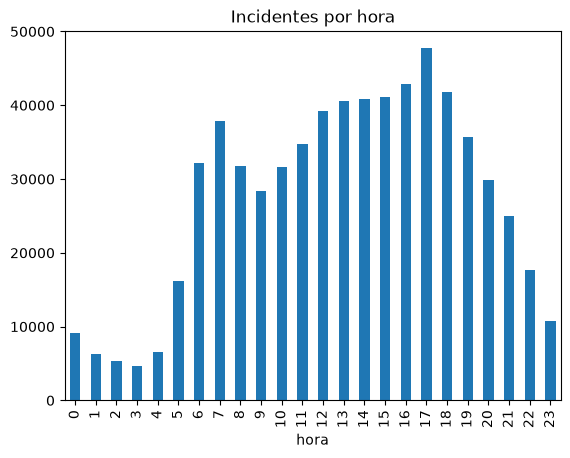

In [7]:
# EDA mínimo
print(df["clase"].value_counts(normalize=True).round(3))
df["hora"].value_counts().sort_index().plot.bar()
plt.title("Incidentes por hora"); plt.show()

# 2. Preparación
- **hora y día** son circulares (las 23h están al lado de las 0h): se pasan a seno y coseno.
- **Se agrupa por DÓNDE y CUÁNDO** (lat, lon, hora, día). La **clase del incidente NO entra al clustering**: al probarlo, las dummies 0/1 dominaban la distancia y los grupos resultaron ser simplemente "una clase por grupo". La clase se usa después, en el perfil, para describir cada grupo.
- Sin escalar, lat/lon (decimales) y seno/coseno pesan distinto: StandardScaler.
- Faltantes: se eliminan las filas sin coordenadas (~6 %) porque sin ellas no hay análisis espacial; atípicos geográficos fuera de Medellín se descartan como errores de geocodificación.

In [ ]:
top = df["clase"].value_counts().index[:4]
df["clase_g"] = np.where(df["clase"].isin(top), df["clase"], "Otras")   # solo para el perfil

X = pd.DataFrame({
    "lat": df["lat"], "lon": df["lon"],
    "hora_sin": np.sin(2 * np.pi * df["hora"] / 24), "hora_cos": np.cos(2 * np.pi * df["hora"] / 24),
    "dia_sin": np.sin(2 * np.pi * df["dia_semana"] / 7), "dia_cos": np.cos(2 * np.pi * df["dia_semana"] / 7),
})

scaler = StandardScaler()
Xs = scaler.fit_transform(X)          # en clustering se ajusta con todo el dataset
print(Xs.shape)

N_SIL = 10000

(657755, 6)


# 3. K-means: elegir K con codo + silueta

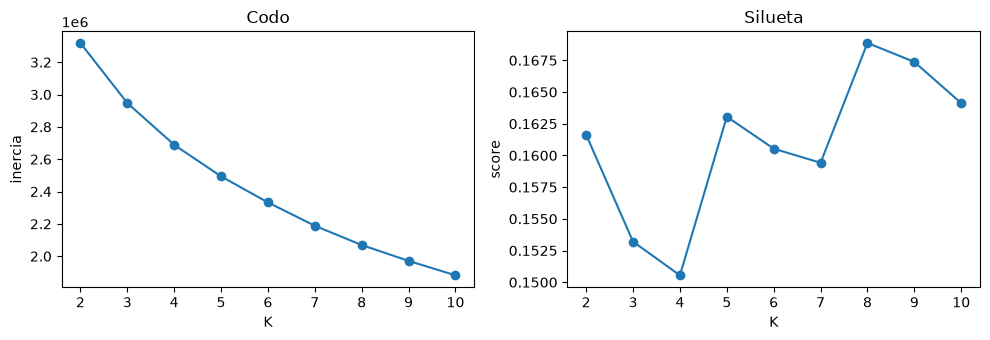

{2: np.float64(0.162), 3: np.float64(0.153), 4: np.float64(0.151), 5: np.float64(0.163), 6: np.float64(0.161), 7: np.float64(0.159), 8: np.float64(0.169), 9: np.float64(0.167), 10: np.float64(0.164)}


In [9]:
ks = range(2, 11)
inercias = [KMeans(k, n_init=10, random_state=42).fit(Xs).inertia_ for k in ks]
siluetas = [silhouette_score(Xs, KMeans(k, n_init=10, random_state=42).fit_predict(Xs),
                             sample_size=N_SIL, random_state=0) for k in ks]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ks, inercias, "o-"); ax[0].set(title="Codo", xlabel="K", ylabel="inercia")
ax[1].plot(ks, siluetas, "o-"); ax[1].set(title="Silueta", xlabel="K", ylabel="score")
plt.tight_layout(); plt.savefig("outputs/A1_codo_silueta.png", dpi=150); plt.show()
print(dict(zip(ks, np.round(siluetas, 3))))

km
0    106902
1    113634
2    108301
3    100360
4     97726
5    130832
Name: count, dtype: int64


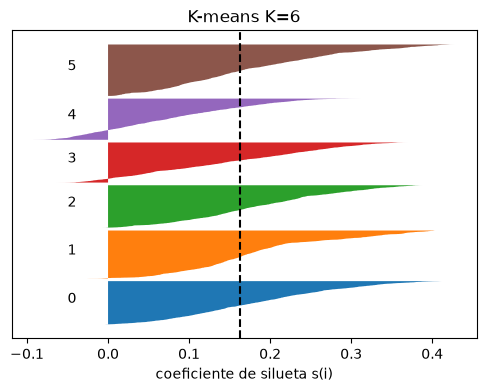

In [10]:
K = 6

kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df["km"] = kmeans.fit_predict(Xs)
print(df["km"].value_counts().sort_index())

# Diagrama de silueta (receta del profe) sobre una muestra
idx = np.random.default_rng(0).choice(len(df), N_SIL, replace=False)
s = silhouette_samples(Xs[idx], df["km"].values[idx])
lab = df["km"].values[idx]
y0 = 0
plt.figure(figsize=(6, 4))
for c in np.unique(lab):
    s_c = np.sort(s[lab == c])
    plt.fill_betweenx(np.arange(y0, y0 + len(s_c)), 0, s_c)
    plt.text(-0.05, y0 + len(s_c) / 2, str(c))
    y0 += len(s_c) + 100
plt.axvline(s.mean(), ls="--", color="k"); plt.yticks([])
plt.xlabel("coeficiente de silueta s(i)"); plt.title(f"K-means K={K}")
plt.savefig("outputs/A2_diagrama_silueta.png", dpi=150); plt.show()

# 4. Clustering jerárquico
Necesita todas las distancias entre pares: con más de 650 mil filas no cabe en memoria, así que se usa una **muestra aleatoria de 4000** (decisión a justificar en el informe).

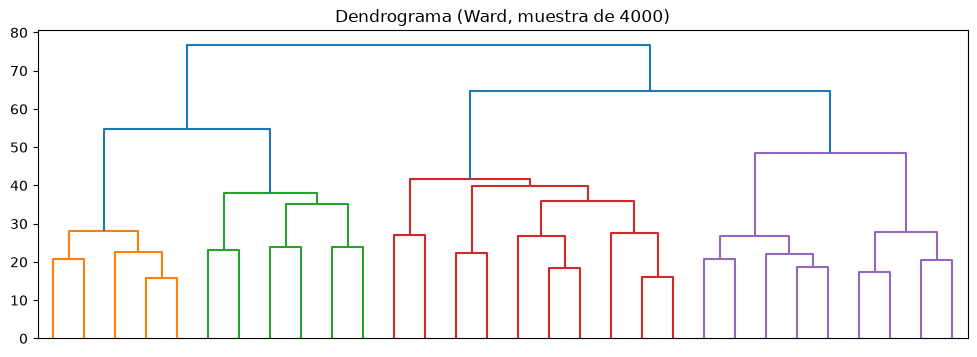

jer
2    989
4    898
5    590
6    582
1    551
3    390
Name: count, dtype: int64

In [11]:
muestra = df.sample(4000, random_state=42)
Xm = Xs[muestra.index]

Z = linkage(Xm, method="ward")                       # 1. construir el árbol
plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)   # 2. dibujarlo (solo los últimos 30 cortes)
plt.title("Dendrograma (Ward, muestra de 4000)")
plt.savefig("outputs/A3_dendrograma.png", dpi=150); plt.show()

muestra = muestra.assign(jer=fcluster(Z, t=K, criterion="maxclust"))   # 3. cortar en K grupos
muestra["jer"].value_counts()

In [12]:
# Comparar linkages (single encadena; ward/complete dan grupos más balanceados)
for met in ["single", "complete", "average", "ward"]:
    print(met, np.bincount(fcluster(linkage(Xm, method=met), t=K, criterion="maxclust"))[1:])

# Jerárquico vs K-means sobre la misma muestra: tabla cruzada (las etiquetas son arbitrarias)
pd.crosstab(muestra["km"], muestra["jer"])

single [  15    1 3981    1    1    1]
complete [  43    1  549 1825   58 1524]
average [  27   15 3932   14   11    1]
ward [551 989 390 898 590 582]


jer,1,2,3,4,5,6
km,,,,,,
0,21,12,230,55,294,8
1,0,130,7,479,0,22
2,6,90,0,29,43,540
3,475,70,53,5,49,1
4,9,19,99,294,182,9
5,40,668,1,36,22,2


# 5. DBSCAN (haversine): puntos calientes en el mapa
Igual que el caso California de la clase:
- lat/lon NO se escalan (ya comparten unidad): métrica haversine, coordenadas en radianes, eps = km / 6371 para que se lea en kilómetros.
- Solo lugar: un hotspot es un sitio. La hora y la clase se miran después, en el perfil.
- Truco por tamaño: muchos incidentes ocurren en la misma esquina. Se agrupan por coordenada redondeada (~11 m) y cada punto único pesa lo que repite (`sample_weight`). Es el mismo DBSCAN, solo más rápido.

In [13]:
R = 6371   # radio de la Tierra (km)
df["lat_r"] = df["lat"].round(4)
df["lon_r"] = df["lon"].round(4)
pts = df.groupby(["lat_r", "lon_r"]).size().rename("w").reset_index()
coords = np.radians(pts[["lat_r", "lon_r"]])
print(f"{len(pts):,} puntos únicos de {len(df):,} incidentes")

21,399 puntos únicos de 657,755 incidentes


In [ ]:
min_samples = 30
nn = NearestNeighbors(n_neighbors=min_samples, metric="haversine", algorithm="ball_tree").fit(coords)
dist, _ = nn.kneighbors(coords)
k_dist = np.sort(dist[:, -1]) * R * 1000
plt.plot(k_dist); plt.yscale("log")
plt.xlabel("puntos ordenados"); plt.ylabel(f"distancia al vecino {min_samples} (m)")
plt.savefig("outputs/A4_k_distancia.png", dpi=150); plt.show()

In [15]:
def correr_dbscan(eps_m, min_samples):
    db = DBSCAN(eps=(eps_m / 1000) / R, min_samples=min_samples,
                metric="haversine", algorithm="ball_tree")
    return db.fit_predict(coords, sample_weight=pts["w"])

filas = []
for eps_m in [30, 50, 75, 100, 150]:
    for ms in [100, 300, 600, 1000]:
        lab = correr_dbscan(eps_m, ms)
        pesos = pts["w"].groupby(lab).sum()          # incidentes por grupo
        ruido = pesos.get(-1, 0) / pesos.sum()
        validos = pesos.drop(-1, errors="ignore")
        filas.append((eps_m, ms, len(validos), round(ruido, 3),
                      round(validos.max() / pesos.sum(), 3) if len(validos) else 0))
malla = pd.DataFrame(filas, columns=["eps_m", "min_samples", "n_hotspots", "pct_ruido", "pct_en_el_mayor"])
malla

,eps_m,min_samples,n_hotspots,pct_ruido,pct_en_el_mayor
0,30,100,1477,0.354,0.006
1,30,300,380,0.631,0.006
2,30,600,148,0.774,0.006
3,30,1000,50,0.885,0.006
4,50,100,1393,0.254,0.013
5,50,300,405,0.540,0.010
6,50,600,160,0.708,0.010
7,50,1000,68,0.828,0.010
8,75,100,933,0.123,0.093
9,75,300,414,0.398,0.026


In [16]:
EPS_M, MIN_SAMPLES = 150, 1000

pts["db"] = correr_dbscan(EPS_M, MIN_SAMPLES)
df = df.merge(pts[["lat_r", "lon_r", "db"]], on=["lat_r", "lon_r"])

n_hot = df.loc[df["db"] != -1, "db"].nunique()
pct_ruido = (df["db"] == -1).mean()
pct_mayor = df["db"].value_counts().drop(-1, errors="ignore").max() / len(df) if n_hot else 0
print(f"{n_hot} hotspots · {pct_ruido:.0%} ruido · el grupo más grande tiene {pct_mayor:.0%} de los incidentes")
if pct_mayor > 0.3:
    print("ATENCIÓN: un solo grupo domina. Baja eps o sube min_samples.")

# Silueta sin ruido, en haversine, con sample_size (como en California). Se reporta junto al % de ruido.
mask = (df["db"] != -1).to_numpy()
c_all = np.radians(df[["lat", "lon"]].to_numpy())
if n_hot >= 2:
    sil_db = silhouette_score(c_all[mask], df["db"].to_numpy()[mask], metric="haversine",
                              sample_size=N_SIL, random_state=0)
else:
    sil_db = np.nan
print("silueta DBSCAN (sin ruido):", round(sil_db, 3))

82 hotspots · 39% ruido · el grupo más grande tiene 26% de los incidentes
silueta DBSCAN (sin ruido): 0.134


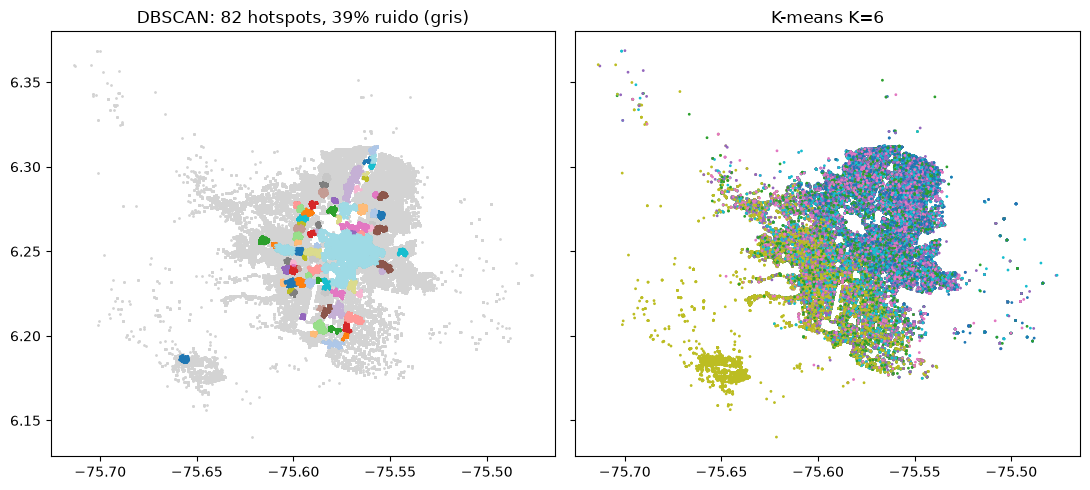

In [17]:
# Mapa: DBSCAN vs K-means
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
r = df["db"] == -1
ax[0].scatter(df.loc[r, "lon"], df.loc[r, "lat"], s=1, c="lightgray")
ax[0].scatter(df.loc[~r, "lon"], df.loc[~r, "lat"], s=1, c=df.loc[~r, "db"] % 20, cmap="tab20")
ax[0].set_title(f"DBSCAN: {n_hot} hotspots, {r.mean():.0%} ruido (gris)")
ax[1].scatter(df["lon"], df["lat"], s=1, c=df["km"], cmap="tab10")
ax[1].set_title(f"K-means K={K}")
plt.tight_layout(); plt.savefig("outputs/A5_mapas.png", dpi=150); plt.show()

# 6. Comparación
La silueta **no** es comparable entre métodos con geometrías distintas (K-means y jerárquico agrupan por lugar+hora+día; DBSCAN solo por lugar): hay que leerla junto con las observaciones.

In [18]:
comparacion = pd.DataFrame({
    "método": ["K-means", "Jerárquico (Ward)", "DBSCAN haversine"],
    "parámetros": [f"K={K}", f"corte K={K}", f"eps={EPS_M} m, min_samples={MIN_SAMPLES}"],
    "espacio": ["lugar+hora+día"] * 2 + ["solo lugar"],
    "grupos": [K, K, n_hot],
    "% ruido": [0, 0, round(pct_ruido * 100, 1)],
    "silueta": [round(silhouette_score(Xs, df["km"], sample_size=N_SIL, random_state=0), 3),
                round(silhouette_score(Xm, muestra["jer"]), 3), round(sil_db, 3)],
})
comparacion

,método,parámetros,espacio,grupos,% ruido,silueta
0,K-means,K=6,lugar+hora+día,6,0.0,0.161
1,Jerárquico (Ward),corte K=6,lugar+hora+día,6,0.0,0.116
2,DBSCAN haversine,"eps=150 m, min_samples=1000",solo lugar,82,39.1,0.134


# 7. Interpretación: perfiles y validación externa
Recién aquí se mira la gravedad. Si grupos formados **sin** ella difieren en la tasa de víctimas, la estructura es real y sirve para decidir.

In [19]:
dummies = pd.get_dummies(df["clase_g"], prefix="clase", dtype=float)
base = pd.concat([df[["hora", "fin_de_semana", "con_victimas"]], dummies], axis=1)

perfil = base.groupby(df["km"]).mean().round(2)
perfil.insert(0, "n", df["km"].value_counts().sort_index())
perfil.insert(1, "comuna_top", df.groupby("km")["comuna"].agg(moda))
perfil

,n,comuna_top,hora,fin_de_semana,con_victimas,clase_Atropello,clase_Caida Ocupante,clase_Choque,clase_Otras,clase_Otro
km,,,,,,,,,,
0,106902,La Candelaria,17.35,0.01,0.59,0.14,0.08,0.63,0.03,0.12
1,113634,La Candelaria,8.65,0.00,0.58,0.09,0.07,0.67,0.04,0.14
2,108301,La Candelaria,9.15,0.12,0.58,0.09,0.08,0.66,0.03,0.14
3,100360,La Candelaria,15.58,0.59,0.65,0.14,0.09,0.60,0.03,0.14
4,97726,El Poblado,16.32,0.06,0.49,0.08,0.06,0.73,0.03,0.11
5,130832,La Candelaria,12.93,0.65,0.52,0.11,0.06,0.70,0.03,0.10


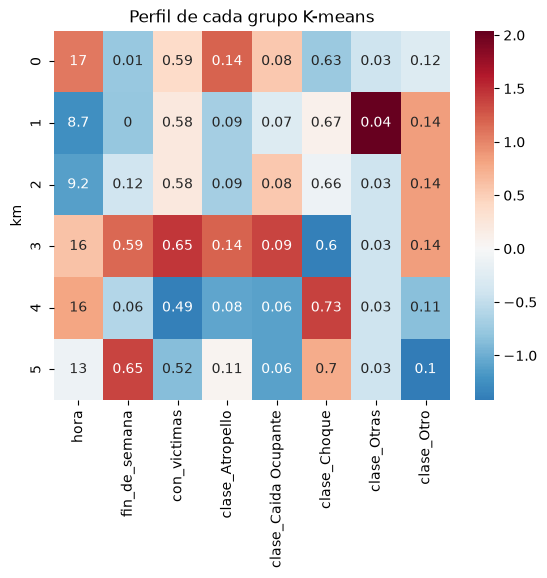

In [ ]:

num = perfil.drop(columns=["n", "comuna_top"])
sns.heatmap((num - num.mean()) / num.std(), annot=num, cmap="RdBu_r", center=0)
plt.title("Perfil de cada grupo K-means"); plt.savefig("outputs/A6_perfiles.png", dpi=150); plt.show()

In [21]:
# Validación externa: χ² de independencia entre grupo y víctimas
tabla = pd.crosstab(df["km"], df["con_victimas"])
chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
print(f"Tasa global de víctimas: {df['con_victimas'].mean():.3f} | χ² p-valor = {p:.3g}")
print("Frecuencia esperada mínima:", esperadas.min().round(1))
print("OJO: con n tan grande casi todo sale 'significativo'; mira la DIFERENCIA en tasa, no solo el p-valor.")

Tasa global de víctimas: 0.567 | χ² p-valor = 0
Frecuencia esperada mínima: 42322.1
OJO: con n tan grande casi todo sale 'significativo'; mira la DIFERENCIA en tasa, no solo el p-valor.


In [22]:
# DBSCAN: los 10 hotspots más grandes vs ruido (los incidentes aislados NO son basura: son información)
grandes = df.loc[df["db"] != -1, "db"].value_counts().head(10).index
df["zona"] = np.where(df["db"].isin(grandes), df["db"], np.where(df["db"] == -1, -1, -2))
df[df["zona"] != -2].groupby("zona").agg(
    n=("hora", "size"), hora_media=("hora", "mean"), fin_semana=("fin_de_semana", "mean"),
    clase_top=("clase_g", moda), comuna_top=("comuna", moda),
    tasa_victimas=("con_victimas", "mean")).round(2)

,n,hora_media,fin_semana,clase_top,comuna_top,tasa_victimas
zona,,,,,,
-1,257021,13.41,0.28,Choque,El Poblado,0.66
1,6123,13.01,0.17,Choque,El Poblado,0.40
7,7133,13.27,0.20,Choque,El Poblado,0.33
9,13332,12.91,0.17,Choque,El Poblado,0.42
10,5166,12.98,0.19,Choque,Guayabal,0.48
12,5462,12.90,0.18,Choque,Guayabal,0.52
19,167912,12.99,0.22,Choque,La Candelaria,0.48
39,7501,13.20,0.25,Choque,La América,0.53
52,14831,12.95,0.23,Choque,Aranjuez,0.52


In [23]:
# Cruce de métodos: patrones que persisten = estructura real
pd.crosstab(df["km"], np.where(df["db"] == -1, "aislado", "en hotspot"), normalize="index").round(2)

col_0,aislado,en hotspot
km,,
0,0.38,0.62
1,0.34,0.66
2,0.36,0.64
3,0.44,0.56
4,0.47,0.53
5,0.37,0.63


# 8. Perfilado
Para la solución más útil (K-means: cuándo y qué tipo de incidente; DBSCAN: dónde): medias o medianas, gráficos, **nombre de negocio** y **acción concreta** para el decisor.

In [24]:
# Medianas y medias de las variables que caracterizan cada grupo
df["noche"] = ((df["hora"] >= 22) | (df["hora"] <= 5)).astype(int)
df["hora_pico"] = df["hora"].isin([6, 7, 8, 17, 18, 19]).astype(int)
resumen = df.groupby("km").agg(
    n=("hora", "size"),
    hora_mediana=("hora", "median"),
    pct_noche=("noche", "mean"),
    pct_hora_pico=("hora_pico", "mean"),
    pct_fin_semana=("fin_de_semana", "mean"),
    tasa_victimas=("con_victimas", "mean"),
).round(2)
resumen["pct_del_total"] = (resumen["n"] / len(df)).round(3)
resumen["clase_top"] = df.groupby("km")["clase_g"].agg(moda)
resumen["comuna_top"] = df.groupby("km")["comuna"].agg(moda)
resumen

,n,hora_mediana,pct_noche,pct_hora_pico,pct_fin_semana,tasa_victimas,pct_del_total,clase_top,comuna_top
km,,,,,,,,,
0,106902,18.0,0.06,0.46,0.01,0.59,0.163,Choque,La Candelaria
1,113634,8.0,0.09,0.45,0.00,0.58,0.173,Choque,La Candelaria
2,108301,9.0,0.09,0.37,0.12,0.58,0.165,Choque,La Candelaria
3,100360,19.0,0.46,0.25,0.59,0.65,0.153,Choque,La Candelaria
4,97726,17.0,0.04,0.39,0.06,0.49,0.149,Choque,El Poblado
5,130832,13.0,0.00,0.18,0.65,0.52,0.199,Choque,La Candelaria


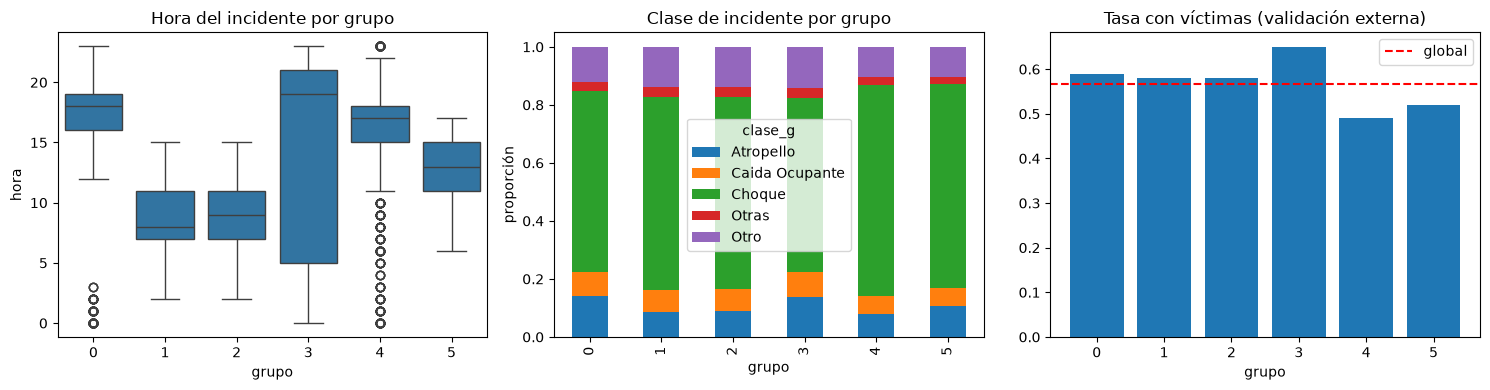

In [25]:
# Gráficos del perfil: hora por grupo, mezcla de clases y tasa de víctimas
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df.sample(50000, random_state=1), x="km", y="hora", ax=ax[0])
ax[0].set(title="Hora del incidente por grupo", xlabel="grupo")
pd.crosstab(df["km"], df["clase_g"], normalize="index").plot.bar(stacked=True, ax=ax[1])
ax[1].set(title="Clase de incidente por grupo", xlabel="grupo", ylabel="proporción")
ax[2].bar(resumen.index.astype(str), resumen["tasa_victimas"])
ax[2].axhline(df["con_victimas"].mean(), color="r", ls="--", label="global")
ax[2].set(title="Tasa con víctimas (validación externa)", xlabel="grupo"); ax[2].legend()
plt.tight_layout(); plt.savefig("outputs/A7_perfil_grupos.png", dpi=150); plt.show()

In [ ]:

nombres = {
    0: ("Pico de la tarde laboral",
        "Reforzar agentes de tránsito de 16 h a 19 h, de lunes a viernes, en los corredores de mayor flujo"),
    1: ("Pico de la mañana laboral",
        "Reforzar agentes de tránsito de 6 h a 9 h, de lunes a viernes, en las entradas a la ciudad y corredores principales"),
    2: ("Media mañana con parte de fin de semana",
        "Mantener cobertura de tránsito de 8 h a 11 h y revisar los días en que se concentra para ajustar los turnos"),
    3: ("Noche y madrugada de fin de semana (el más grave)",
        "Operativos de alcoholemia y control de velocidad de viernes a domingo de 22 h a 5 h, y despacho de ambulancia prioritario en reportes nocturnos"),
    4: ("Tarde en El Poblado, incidentes más leves",
        "Atender con tránsito sin ambulancia por defecto (prioridad baja en el despacho); ambulancia solo si el reporte indica heridos"),
    5: ("Fin de semana de día",
        "Reforzar el control sábados y domingos de 11 h a 15 h en corredores recreativos y salidas de la ciudad"),
}

perfilado = resumen[["n", "pct_del_total", "hora_mediana", "pct_noche", "tasa_victimas", "clase_top", "comuna_top"]].copy()
perfilado["nombre"] = [nombres[k][0] for k in perfilado.index]
perfilado["accion"] = [nombres[k][1] for k in perfilado.index]
perfilado.to_csv("outputs/A8_perfilado.csv")
perfilado

,n,pct_del_total,hora_mediana,pct_noche,tasa_victimas,clase_top,comuna_top,nombre,accion
km,,,,,,,,,
0,106902,0.163,18.0,0.06,0.59,Choque,La Candelaria,Pico de la tarde laboral,"Reforzar agentes de tránsito de 16 h a 19 h, d..."
1,113634,0.173,8.0,0.09,0.58,Choque,La Candelaria,Pico de la mañana laboral,"Reforzar agentes de tránsito de 6 h a 9 h, de ..."
2,108301,0.165,9.0,0.09,0.58,Choque,La Candelaria,Media mañana con parte de fin de semana,Mantener cobertura de tránsito de 8 h a 11 h y...
3,100360,0.153,19.0,0.46,0.65,Choque,La Candelaria,Noche y madrugada de fin de semana (el más grave),Operativos de alcoholemia y control de velocid...
4,97726,0.149,17.0,0.04,0.49,Choque,El Poblado,"Tarde en El Poblado, incidentes más leves",Atender con tránsito sin ambulancia por defect...
5,130832,0.199,13.0,0.00,0.52,Choque,La Candelaria,Fin de semana de día,Reforzar el control sábados y domingos de 11 h...


# 9. Puente a la Parte B: DBSCAN + KNN
DBSCAN no tiene `predict()`. Para asignar hotspot a incidentes **nuevos** (el test 2023-2025) se entrena un KNN solo con los puntos núcleo del train, y lo que queda lejos de todo núcleo es "aislado" (-1). Así el hotspot se ajusta solo con train y no hay fuga de datos.

In [27]:
train = df[df["anio"] <= 2022]
test = df[df["anio"] > 2022]

pt = train.groupby(["lat_r", "lon_r"]).size().rename("w").reset_index()
ct = np.radians(pt[["lat_r", "lon_r"]])
dbt = DBSCAN(eps=(EPS_M / 1000) / R, min_samples=MIN_SAMPLES, metric="haversine", algorithm="ball_tree")
lab_t = dbt.fit_predict(ct, sample_weight=pt["w"])

nucleos = ct.to_numpy()[dbt.core_sample_indices_]
et_nucleos = lab_t[dbt.core_sample_indices_]
knn = KNeighborsClassifier(n_neighbors=1, metric="haversine").fit(nucleos, et_nucleos) if len(nucleos) else None

def asignar_hotspot(d):
    c = np.radians(d[["lat", "lon"]].to_numpy())
    dist, _ = knn.kneighbors(c, n_neighbors=1)
    y = knn.predict(c)
    y[dist[:, 0] > (EPS_M / 1000) / R] = -1       # lejos de todo núcleo = aislado
    return y

if len(test) and len(nucleos):
    print("% aislados en test:", (asignar_hotspot(test) == -1).mean().round(3))
else:
    print("Sin puntos núcleo en train: ajusta EPS_M y MIN_SAMPLES.")

df[["lat", "lon", "hora", "dia_semana", "anio", "clase", "comuna", "con_victimas", "km", "db"]] \
    .to_csv("outputs/parte_A_etiquetas.csv", index=False)

% aislados en test: 0.527
